# Simple linear regression

### Notebook setup

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (6, 1.6)},
)
%matplotlib inline
%config InlineBackend.figure_format = "retina"

<Figure size 640x480 with 0 Axes>

In [4]:
# Simplified int and float __repr__
np.set_printoptions(legacy='1.25')

In [5]:
from ministats import plot_reg

### (A) Perfect fit

In [6]:
x = np.linspace(0,20,21)
b0 = 5; b1 = 2.0
y = b0 + b1*x
y

array([ 5.,  7.,  9., 11., 13., 15., 17., 19., 21., 23., 25., 27., 29.,
       31., 33., 35., 37., 39., 41., 43., 45.])

In [7]:
df1 = pd.DataFrame({'X':x, 'Y':y})
df1.head(3)

,X,Y
0,0.0,5.0
1,1.0,7.0
2,2.0,9.0


<Axes: xlabel='x', ylabel='y'>

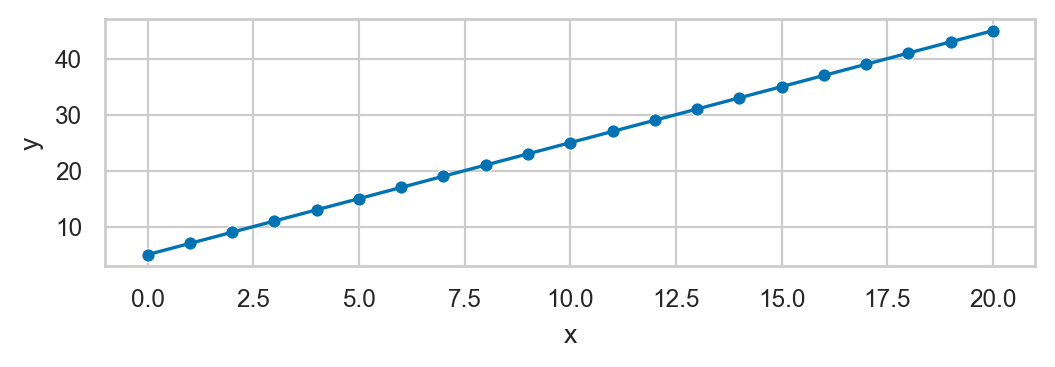

In [8]:
# Fit the linear model
import statsmodels.formula.api as smf
lm1 = smf.ols("y ~ 1 + x", data=df1).fit()

plot_reg(lm1)

In [9]:
# Print the model fit summary table
lm1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.150e+32
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          6.73e-294
Time:                        13:38:45   Log-Likelihood:                 662.05
No. Observations:                  21   AIC:                            -1320.
Df Residuals:                      19   BIC:                            -1318.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.0000   2.18e-15   2.29e+15      0.000       5.000       5.000
x              2.0000   1.86e-16   1.07e+16      0.000       2.000       2.000
==============================================================================
Omnibus:                        6.640   Durbin-Watson:                   0.082
Prob(Omnibus):                  0.036   Jarque-Bera (JB):                1.801
Skew:                           0.122   Prob(JB):                        0.406
Kurtosis:                       1.586   Cond. No.                         22.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### (B) Perfect fit with tiny error added to avoid divide by zero

In [10]:
x = np.linspace(0,20,21)
b0 = 5; b1 = 2.0

from scipy.stats import norm
rvN = norm(0,0.01)
y = b0 + b1*x + rvN.rvs(len(x))
#y

In [11]:
df2 = pd.DataFrame({'X':x, 'Y':y})
#df2.columns, df2.head(4)

In [12]:
# Fit the linear model
import statsmodels.formula.api as smf
lm2 = smf.ols("y ~ 1 + x", data=df2).fit()
#plot_reg(lm2)
# Print the model fit summary table
lm2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.066e+07
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           1.92e-60
Time:                        13:38:45   Log-Likelihood:                 67.908
No. Observations:                  21   AIC:                            -131.8
Df Residuals:                      19   BIC:                            -129.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.9934      0.004   1182.228      0.000       4.985       5.002
x              2.0005      0.000   5537.175      0.000       2.000       2.001
==============================================================================
Omnibus:                        0.458   Durbin-Watson:                   2.735
Prob(Omnibus):                  0.795   Jarque-Bera (JB):                0.265
Skew:                          -0.257   Prob(JB):                        0.876
Kurtosis:                       2.804   Cond. No.                         22.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### (C) Perfect fit with adjustable error

In [13]:
x = np.linspace(0,20,21)
b0 = 5; b1 = 2.0
print("USER: Change the value of DATAPOINT_ERROR")
DATAPOINT_ERROR = 10.0
from scipy.stats import norm
rvN = norm(0, DATAPOINT_ERROR)
y = b0 + b1*x + rvN.rvs(len(x))
#y

USER: Change the value of DATAPOINT_ERROR


In [14]:
df3 = pd.DataFrame({'X':x, 'Y':y})
#df3.columns, df3.head(4)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.680
Model:                            OLS   Adj. R-squared:                  0.664
Method:                 Least Squares   F-statistic:                     40.47
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           4.20e-06
Time:                        13:38:45   Log-Likelihood:                -75.926
No. Observations:                  21   AIC:                             155.9
Df Residuals:                      19   BIC:                             157.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.4673      3.984      2.125      0.047       0.129      16.805
x              2.1677      0.341      6.361      0.000       1.455       2.881
==============================================================================
Omnibus:                        0.783   Durbin-Watson:                   1.516
Prob(Omnibus):                  0.676   Jarque-Bera (JB):                0.133
Skew:                           0.176   Prob(JB):                        0.936
Kurtosis:                       3.167   Cond. No.                         22.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

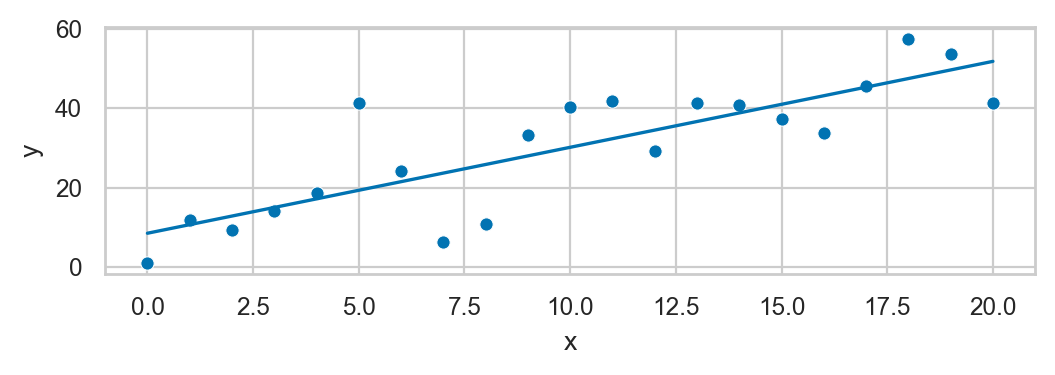

In [15]:
# Fit the linear model
import statsmodels.formula.api as smf
lm3 = smf.ols("y ~ 1 + x", data=df3).fit()
plot_reg(lm3)
# Print the model fit summary table
lm3.summary()

### (D) Quadratic term added

In [16]:
x = np.linspace(0,20,21)
b0 = 5; b1 = 2.0; b2 = 1.0

DATAPOINT_ERROR = 0.01
from scipy.stats import norm
rvN = norm(0, DATAPOINT_ERROR)
y = b0 + b1*x + b2*x**2
#y = b0 + b1*x + b2*x**2 + rvN.rvs(len(x))
#y

In [17]:
df4 = pd.DataFrame({'X':x, 'Y':y})

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.943
Model:                            OLS   Adj. R-squared:                  0.940
Method:                 Least Squares   F-statistic:                     315.7
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           2.71e-13
Time:                        13:38:45   Log-Likelihood:                -103.02
No. Observations:                  21   AIC:                             210.0
Df Residuals:                      19   BIC:                             212.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -58.3333     14.476     -4.030      0.001     -88.632     -28.035
x             22.0000      1.238     17.767      0.000      19.408      24.592
==============================================================================
Omnibus:                        2.777   Durbin-Watson:                   0.119
Prob(Omnibus):                  0.249   Jarque-Bera (JB):                2.075
Skew:                           0.619   Prob(JB):                        0.354
Kurtosis:                       2.085   Cond. No.                         22.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

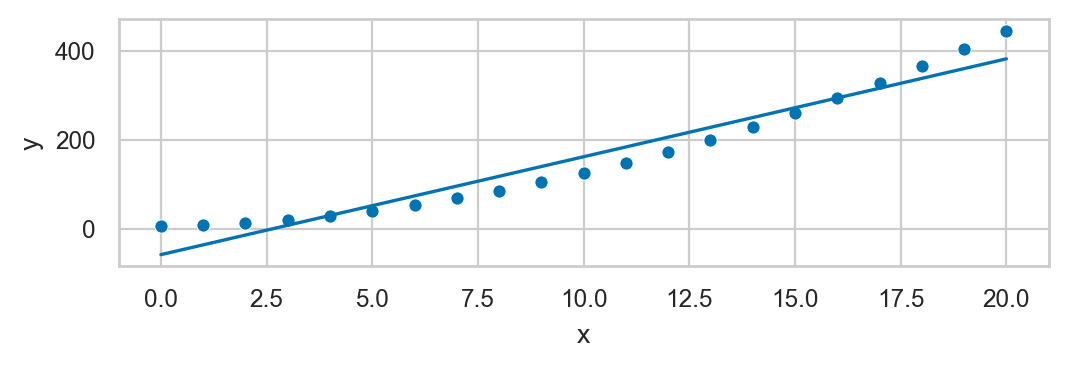

In [18]:
# Fit the linear model
import statsmodels.formula.api as smf
lm4 = smf.ols("y ~ 1 + x", data=df4).fit()
plot_reg(lm4)
# Print the model fit summary table
lm4.summary()

### (E) F-Statistic

In [19]:
print("USER: Change the value of b1 and DATAPOINT_ERROR to see the effect on F-Statistic")
x = np.linspace(0,20,21)
b0 = 5;
b1 = 0.2
DATAPOINT_ERROR = 5.0

from scipy.stats import norm
rvN = norm(0, DATAPOINT_ERROR)

y = b0 + b1*x + rvN.rvs(len(x))

USER: Change the value of b1 and DATAPOINT_ERROR to see the effect on F-Statistic


In [20]:
df5 = pd.DataFrame({'X':x, 'Y':y})

In [21]:
# Fit the linear model
import statsmodels.formula.api as smf
lm5 = smf.ols("y ~ 1 + x", data=df5).fit()
#plot_reg(lm2)
# Print the model fit summary table
print(f"Fitted slope coefficient, (input was {b1}): {lm5.params['x']} +- {lm5.bse['x']}")
print("F-Statistic: fvalue, f_pvalue: %.2f %.1f" %  (lm5.fvalue, lm5.f_pvalue))

Fitted slope coefficient, (input was 0.2): 0.2313975538162314 +- 0.14826577655051162
F-Statistic: fvalue, f_pvalue: 2.44 0.1


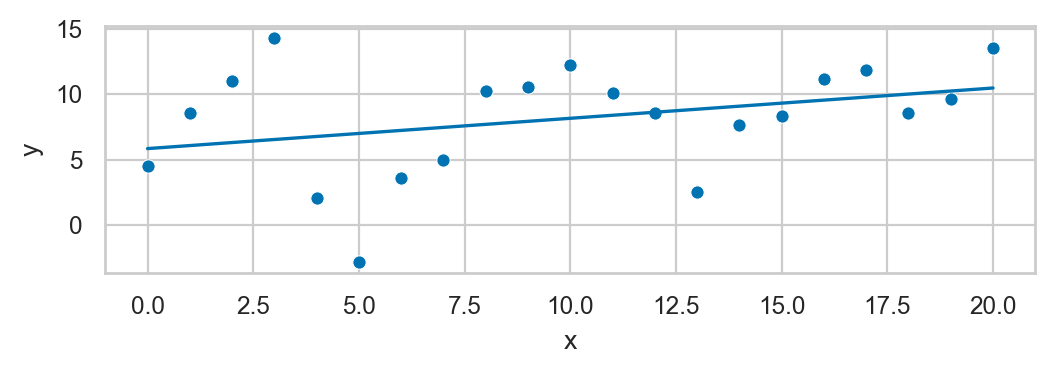

In [22]:
plot_reg(lm5);